# Checkpoint 3 | Clasificador TF-IDF de AG News

Comparación reproducible de Naive Bayes, Regresión Logística y SVM lineal sobre el corpus de la cátedra. El test no interviene en la selección de modelos.

## Preparación
Ejecutar este notebook desde la raíz del repositorio o desde la carpeta `notebooks/`. En Colab, clonar primero el repositorio en `/content/`.

In [1]:
from pathlib import Path
import os, sys, subprocess
raiz = Path.cwd().resolve()
if not (raiz / "checkpoint_3_tfidf").exists():
    raiz = raiz.parent
assert (raiz / "checkpoint_3_tfidf").exists(), "Abrir el notebook desde el repositorio AG News"
print("Repositorio:", raiz)

Repositorio: /mnt/data/AGNews_Checkpoint3_Trabajo


## Entrenamiento y selección
Se comparan modelos sobre 6.400 noticias de desarrollo y 1.600 de validación. Se reentrena el modelo seleccionado con el total de 8.000 noticias de train y se evalúa una única vez sobre el test oficial.

In [2]:
subprocess.run([sys.executable, "-m", "checkpoint_3_tfidf.entrenar"], cwd=raiz, check=True)

AG News: train=8000, test reservado=2000
Preprocesamiento: normalización + SpaCy word-level


Naive Bayes | unigramas: val F1=0.8975 | Accuracy=0.8981


Regresión logística | unigramas: val F1=0.8885 | Accuracy=0.8888


SVM lineal | unigramas: val F1=0.8948 | Accuracy=0.8950


Naive Bayes | unigramas y bigramas: val F1=0.9007 | Accuracy=0.9012


Regresión logística | unigramas y bigramas: val F1=0.8941 | Accuracy=0.8944


SVM lineal | unigramas y bigramas: val F1=0.8948 | Accuracy=0.8950
Seleccionado por F1-macro de validación: Naive Bayes | unigramas y bigramas



CLASIFICACIÓN FINAL
              precision    recall  f1-score   support

    Business     0.8259    0.8540    0.8397       500
    Sci_Tech     0.8780    0.8640    0.8710       500
      Sports     0.9527    0.9660    0.9593       500
       World     0.9091    0.8800    0.8943       500

    accuracy                         0.8910      2000
   macro avg     0.8914    0.8910    0.8911      2000
weighted avg     0.8914    0.8910    0.8911      2000

Accuracy test=0.8910 | F1-macro test=0.8911
Resultados guardados en checkpoint_3_tfidf/outputs/


CompletedProcess(args=['/opt/pyvenv/bin/python', '-m', 'checkpoint_3_tfidf.entrenar'], returncode=0)

## Métricas y resultados

,nombre,algoritmo,max_features,ngram_range,vocabulario_real,accuracy_val,f1_macro_val
0,Naive Bayes | unigramas y bigramas,NB,15000,"(1, 2)",15000,0.901250,0.900724
1,Naive Bayes | unigramas,NB,10000,"(1, 1)",10000,0.898125,0.897526
2,SVM lineal | unigramas y bigramas,SVM,15000,"(1, 2)",15000,0.895000,0.894823
3,SVM lineal | unigramas,SVM,15000,"(1, 1)",10280,0.895000,0.894756
4,Regresión logística | unigramas y bigramas,LR,15000,"(1, 2)",15000,0.894375,0.894117
5,Regresión logística | unigramas,LR,15000,"(1, 1)",10280,0.888750,0.888485


              precision    recall  f1-score   support

    Business     0.8259    0.8540    0.8397       500
    Sci_Tech     0.8780    0.8640    0.8710       500
      Sports     0.9527    0.9660    0.9593       500
       World     0.9091    0.8800    0.8943       500

    accuracy                         0.8910      2000
   macro avg     0.8914    0.8910    0.8911      2000
weighted avg     0.8914    0.8910    0.8911      2000



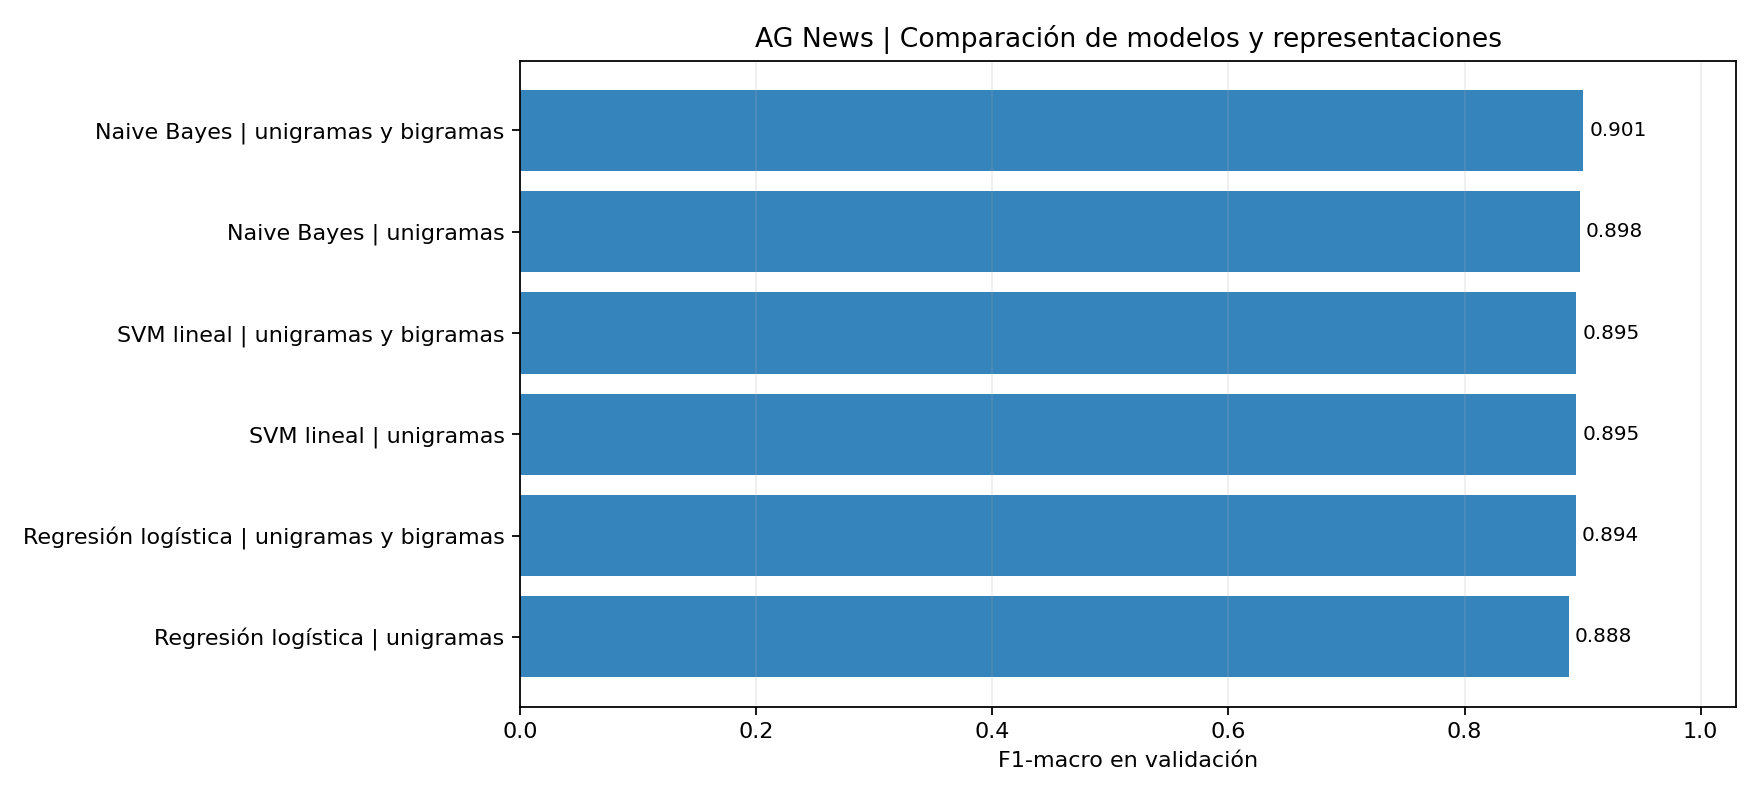

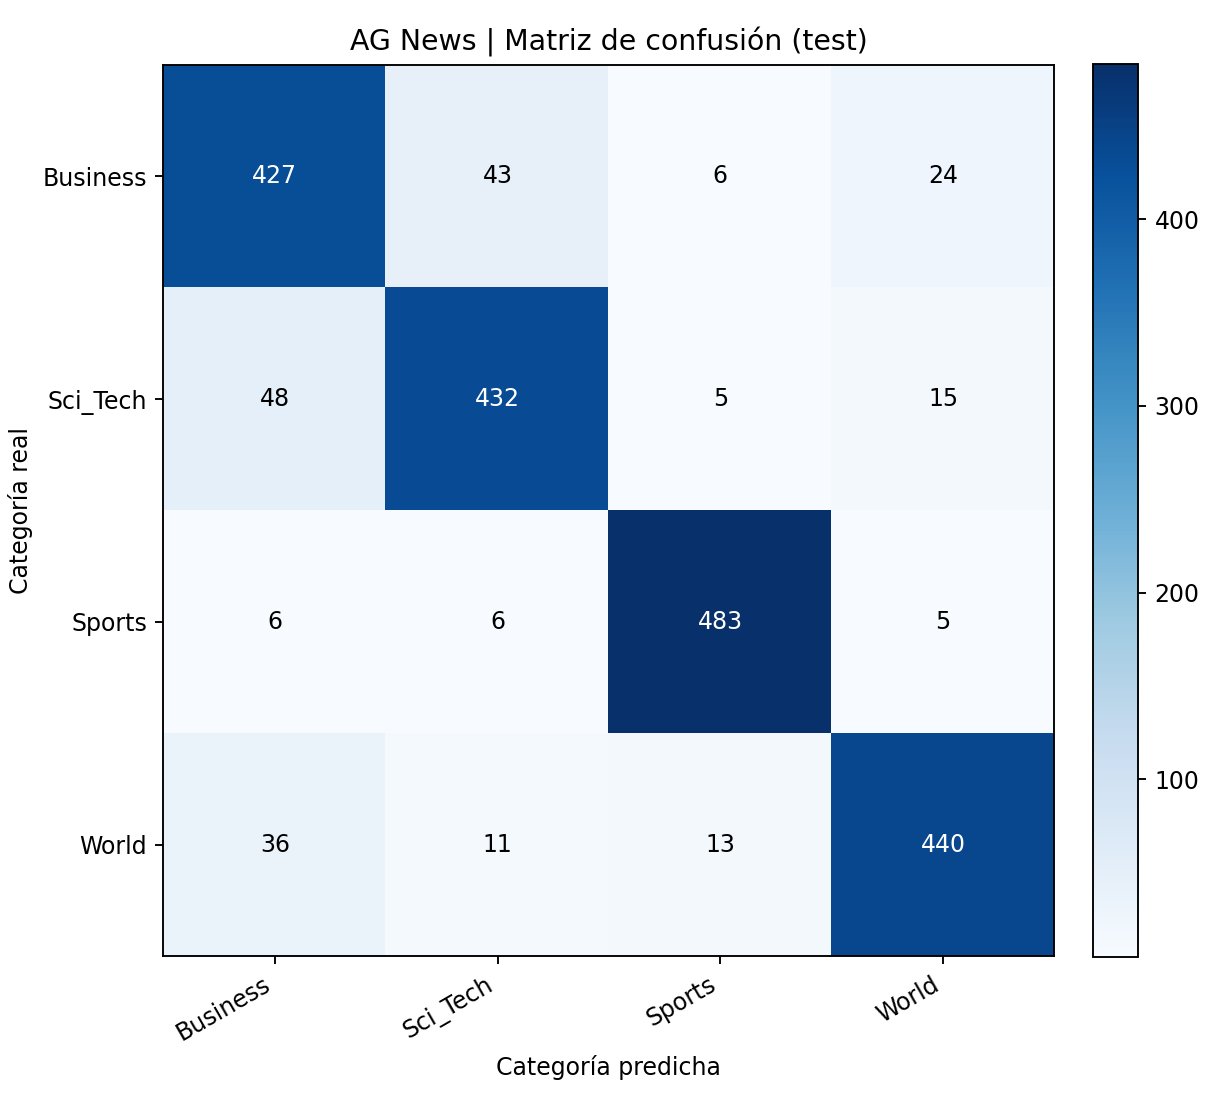

In [3]:
import pandas as pd
from IPython.display import display, Image
salida = raiz / "checkpoint_3_tfidf" / "outputs"
display(pd.read_csv(salida / "comparacion_validacion.csv"))
print((salida / "classification_report.txt").read_text(encoding="utf-8"))
display(Image(filename=str(salida / "comparacion_modelos.png")))
display(Image(filename=str(salida / "matriz_confusion.png")))

## Comprobación de reproducibilidad

In [4]:
subprocess.run([sys.executable, "-m", "checkpoint_3_tfidf.verificar"], cwd=raiz, check=True)

VALIDADO: 2000 noticias | Accuracy=0.8910 | F1-macro=0.8911


CompletedProcess(args=['/opt/pyvenv/bin/python', '-m', 'checkpoint_3_tfidf.verificar'], returncode=0)

## Interpretación
Se elige el modelo por F1-macro de validación. La matriz de confusión permite detectar qué clases comparten vocabulario y requieren mayor análisis. El test oficial no se utiliza para elegir nuevas configuraciones.